# LEC open-field spatial tuning and object moves (50 cm box)

Reads the merged tables and shards of run `a884c28b4e13` of `run_spatial.py --engine of --dataset lec`; it never
opens a data_dic (`RUN_MODE = 'load'`). Settings are the `box50` block of `spatial_of_arenas.json`.
Write-up: `SPATIAL_TUNING.md`, sections dated 2026-10-12. Mice are the replicates: every count is per mouse,
and group statements are binomial tests across the 5 mice.

In [1]:
import os, sys, glob, pickle
import numpy as np, pandas as pd
from scipy import stats
sys.path.insert(0, os.path.abspath('.'))
import spatial_plots as sp
RUN_MODE = 'load'
RUN = '/ceph/behrens/adam_harris/Taskspace_abstraction_lEC/data/spatial/of/a884c28b4e13'
latest = lambda p: sorted(glob.glob(p))[-1]
units = pd.read_csv(latest(f'{RUN}/merged/of_units*.csv'))
sessions = pd.read_csv(latest(f'{RUN}/merged/of_sessions*.csv'))
moves = pd.read_csv(latest(f'{RUN}/merged/of_moves*.csv'))
shards = {os.path.basename(f)[:-4]: pickle.load(open(f, 'rb')) for f in sorted(glob.glob(f'{RUN}/shards/*.pkl'))}
pd.set_option('display.width', 250)
sp.setup_style()
print(len(shards), 'recdays;', units.groupby('mouse').unit.nunique().to_dict(), 'units per mouse (unit rows per session)')

5 recdays; {'ah08': 186, 'ah10': 164, 'ly05': 74, 'ly06': 66, 'ly07': 86} units per mouse (unit rows per session)


## Session classes per mouse

Broad eligible units. Each count is set against the session's chance distribution: one circular shift
applied to every unit at once. p = (1 + chance counts >= observed) / (1 + shifts). Grid is scored but not
classified in the box.

In [2]:
b = sessions[(sessions.pool == 'broad') & sessions.cls.isin(['border', 'spatial', 'hd', 'speed'])].copy()
b['cell'] = b.apply(lambda r: f"{int(r.observed)}/{int(r.n_units)} (p95 {r.chance_p95:.0f}, p {r.p:.3f})", axis=1)
b.pivot_table(index=['mouse', 'session', 'session_type'], columns='cls', values='cell', aggfunc='first')

cls                                         border                       hd                  spatial                    speed
mouse session session_type                                                                                                   
ah08  1       object        8/151 (p95 1, p 0.001)  13/151 (p95 2, p 0.001)  16/151 (p95 1, p 0.001)   8/151 (p95 1, p 0.001)
      4       object        8/150 (p95 1, p 0.001)   6/150 (p95 2, p 0.001)  20/150 (p95 2, p 0.001)   6/150 (p95 1, p 0.001)
      5       object        5/149 (p95 1, p 0.001)  14/149 (p95 2, p 0.001)  11/149 (p95 1, p 0.001)   3/149 (p95 1, p 0.001)
      9       object        8/140 (p95 1, p 0.001)   4/140 (p95 2, p 0.004)   6/140 (p95 1, p 0.001)   1/140 (p95 0, p 0.048)
ah10  1       object        6/119 (p95 0, p 0.001)  21/119 (p95 2, p 0.001)  25/119 (p95 1, p 0.001)   9/119 (p95 0, p 0.001)
      4       object        4/119 (p95 0, p 0.001)  17/119 (p95 2, p 0.001)  18/119 (p95 1, p 0.001)  16/119 (p95 1, p 0.001)
      5       object        5/112 (p95 0, p 0.001)  27/112 (p95 2, p 0.001)  21/112 (p95 1, p 0.001)  17/112 (p95 1, p 0.001)
      9       object        4/112 (p95 0, p 0.001)  15/112 (p95 1, p 0.001)  23/112 (p95 1, p 0.001)   6/112 (p95 0, p 0.001)
ly05  1       object         4/53 (p95 0, p 0.001)   11/53 (p95 1, p 0.001)    6/53 (p95 1, p 0.001)    4/53 (p95 1, p 0.001)
      4       object         1/48 (p95 0, p 0.018)    9/48 (p95 1, p 0.001)    8/48 (p95 1, p 0.001)    6/48 (p95 0, p 0.001)
      5       object         1/54 (p95 0, p 0.021)   12/54 (p95 1, p 0.001)    5/54 (p95 1, p 0.001)    4/54 (p95 0, p 0.001)
      9       object         2/50 (p95 0, p 0.001)   12/50 (p95 1, p 0.001)    6/50 (p95 1, p 0.001)    5/50 (p95 0, p 0.001)
ly06  1       object         1/48 (p95 0, p 0.008)   10/48 (p95 1, p 0.001)   11/48 (p95 1, p 0.001)    5/48 (p95 0, p 0.001)
      4       object         0/45 (p95 0, p 1.000)   11/45 (p95 1, p 0.001)    5/45 (p95 1, p 0.001)    7/45 (p95 0, p 0.001)
      5       object         2/44 (p95 0, p 0.001)   13/44 (p95 1, p 0.001)    5/44 (p95 1, p 0.001)    6/44 (p95 0, p 0.001)
      9       object         4/45 (p95 0, p 0.001)   12/45 (p95 1, p 0.001)    4/45 (p95 1, p 0.001)    8/45 (p95 0, p 0.001)
ly07  1       object         0/68 (p95 0, p 1.000)   22/68 (p95 1, p 0.001)   10/68 (p95 1, p 0.001)    4/68 (p95 0, p 0.001)
      4       object         0/65 (p95 0, p 1.000)   28/65 (p95 1, p 0.001)    4/65 (p95 1, p 0.001)    3/65 (p95 0, p 0.001)
      5       object         1/67 (p95 0, p 0.021)   24/67 (p95 1, p 0.001)    8/67 (p95 1, p 0.001)    8/67 (p95 0, p 0.001)
      9       object         0/67 (p95 0, p 1.000)   23/67 (p95 1, p 0.001)   10/67 (p95 1, p 0.001)    0/67 (p95 0, p 1.000)

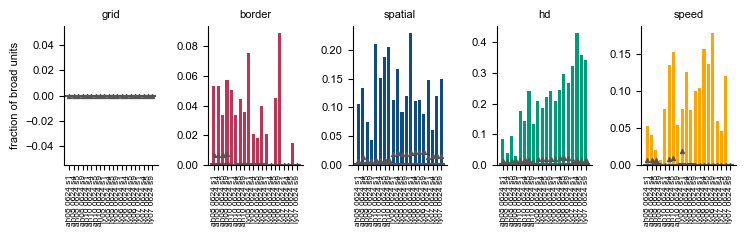

In [3]:
fig = sp.plot_class_counts(sessions)

## Object moves, per mouse and day-pair

Within each day-pair (s1 -> s4, s5 -> s9), corners are V (vacated), S (held by the other object in both),
N (newly occupied) and E (empty in both). One object slides V -> S; its partner moves S -> N diagonally.

Primary classes:
- follow, per object: fires at the old corner, drops there, rises at the new corner, fires there; each
  term at p95, giving about 0.25 % per class;
- generic: the same from V to N;
- trace: rises at V after the object leaves and is significant there, p99 terms;
- object-vector, per object: the map moved by the object's displacement matches better than the unmoved
  map, field beyond the band in both sessions, p99.

Reported: place at V, remapping V -> E, and E changes, the remapping baseline. Each count is set against
the paired-shift chance distribution. The labels are mapped to slider and diagonal mover. The engine also
scores the cross-day pairs (s1 -> s9, s4 -> s5: four different objects); they are left out here.

In [4]:
def role(row, cls):
    movers = dict(m.split(':') for m in row.movers.split(';'))
    if '[' not in cls:
        return cls
    kind, lab = cls.split('[')[0], cls.split('[')[1].rstrip(']')
    return f"{kind}_{'slider' if movers.get(lab, '').startswith('V') else 'diagonal'}"
within = moves.groupby(['recday', 's1', 's2']).cls.transform(lambda c: c.astype(str).str.startswith('follow').any())
mv = moves[within & (moves.cls.astype(str) != '')].copy()
mv['role'] = mv.apply(lambda r: role(r, r.cls), axis=1)
mv['pair'] = mv.s1.astype(int).astype(str) + '->' + mv.s2.astype(int).astype(str)
mv['cell'] = mv.apply(lambda r: f"{int(r.observed)}/{int(r.n_eligible)} (p95 {r.chance_p95:.1f}, p {r.p:.3f})", axis=1)
order = ['follow_slider', 'follow_diagonal', 'trace', 'generic', 'vector_slider', 'vector_diagonal', 'place_vacated', 'remap_E', 'E_change']
mv.pivot_table(index=['mouse', 'pair'], columns='role', values='cell', aggfunc='first')[[c for c in order if c in set(mv.role)]]

role                   follow_slider           follow_diagonal                     trace                   generic             vector_slider           vector_diagonal             place_vacated                   remap_E                  E_change
mouse pair                                                                                                                                                                                                                                          
ah08  1->4  0/162 (p95 0.0, p 1.000)  1/162 (p95 0.0, p 0.029)  0/166 (p95 3.0, p 1.000)  3/162 (p95 0.0, p 0.001)  1/162 (p95 4.0, p 0.733)  1/162 (p95 3.0, p 0.712)  0/162 (p95 0.0, p 1.000)  0/162 (p95 0.0, p 1.000)  2/162 (p95 4.0, p 0.468)
      5->9  0/154 (p95 0.0, p 1.000)  0/154 (p95 0.0, p 1.000)  0/156 (p95 3.0, p 1.000)  1/154 (p95 0.0, p 0.035)  0/154 (p95 3.0, p 1.000)  0/154 (p95 3.0, p 1.000)  1/154 (p95 0.0, p 0.014)  0/154 (p95 0.0, p 1.000)  2/154 (p95 4.0, p 0.437)
ah10  1->4  0/139 (p95 0.0, p 1.000)  0/139 (p95 0.0, p 1.000)  1/142 (p95 2.0, p 0.401)  2/139 (p95 0.0, p 0.001)  0/139 (p95 3.0, p 1.000)  0/139 (p95 3.0, p 1.000)  2/139 (p95 0.0, p 0.001)  2/139 (p95 0.0, p 0.001)  2/139 (p95 4.0, p 0.375)
      5->9  1/131 (p95 0.0, p 0.021)  0/131 (p95 0.0, p 1.000)  0/136 (p95 2.0, p 1.000)  6/131 (p95 0.0, p 0.001)  1/131 (p95 3.0, p 0.601)  0/131 (p95 3.0, p 1.000)  0/131 (p95 0.0, p 1.000)  3/131 (p95 0.0, p 0.001)  6/131 (p95 4.0, p 0.008)
ly05  1->4   0/53 (p95 0.0, p 1.000)   0/53 (p95 0.0, p 1.000)   0/54 (p95 1.0, p 1.000)   1/53 (p95 0.0, p 0.014)   0/53 (p95 2.0, p 1.000)   0/53 (p95 2.0, p 1.000)   0/53 (p95 0.0, p 1.000)   0/53 (p95 0.0, p 1.000)   0/53 (p95 2.0, p 1.000)
      5->9   0/56 (p95 0.0, p 1.000)   0/56 (p95 0.0, p 1.000)   0/56 (p95 1.0, p 1.000)   0/56 (p95 0.0, p 1.000)   3/56 (p95 2.0, p 0.013)   2/56 (p95 2.0, p 0.069)   0/56 (p95 0.0, p 1.000)   0/56 (p95 0.0, p 1.000)   1/56 (p95 2.0, p 0.414)
ly06  1->4   0/58 (p95 0.0, p 1.000)   0/58 (p95 0.0, p 1.000)   0/58 (p95 2.0, p 1.000)   3/58 (p95 0.0, p 0.001)   0/58 (p95 2.0, p 1.000)   1/58 (p95 2.0, p 0.305)   0/58 (p95 0.0, p 1.000)   0/58 (p95 0.0, p 1.000)   1/58 (p95 2.0, p 0.420)
      5->9   1/56 (p95 0.0, p 0.016)   0/56 (p95 0.0, p 1.000)   0/58 (p95 1.0, p 1.000)   2/56 (p95 0.0, p 0.001)   0/56 (p95 2.0, p 1.000)   0/56 (p95 2.0, p 1.000)   1/56 (p95 0.0, p 0.006)   0/56 (p95 0.0, p 1.000)   0/56 (p95 2.0, p 1.000)
ly07  1->4   0/79 (p95 0.0, p 1.000)   0/79 (p95 0.0, p 1.000)   0/79 (p95 2.0, p 1.000)   2/79 (p95 0.0, p 0.002)   0/79 (p95 2.0, p 1.000)   1/79 (p95 2.0, p 0.386)   1/79 (p95 0.0, p 0.011)   0/79 (p95 0.0, p 1.000)   0/79 (p95 3.0, p 1.000)
      5->9   0/79 (p95 0.0, p 1.000)   0/79 (p95 0.0, p 1.000)   0/81 (p95 2.0, p 1.000)   1/79 (p95 0.0, p 0.026)   0/79 (p95 2.0, p 1.000)   0/79 (p95 2.0, p 1.000)   0/79 (p95 0.0, p 1.000)   0/79 (p95 0.0, p 1.000)   2/79 (p95 3.0, p 0.185)

### Per mouse: both day-pairs pooled

Observed counts are summed over the mouse's two day-pairs. The chance distributions are summed draw by
draw; shifts are independent between day-pairs. A mouse is a hit at p <= 0.05. Across mice: hits out of 5,
binomial tail at 0.05.

In [5]:
rows = []
for rd, sh in shards.items():
    mouse = rd.split('_')[0]
    for (s1, s2), rot in sh['rotations'].items():
        m_ = rot.get('object_move') if isinstance(rot, dict) else None
        if not m_ or 'classes' not in m_ or not m_['layout']['movers']:
            continue
        movers = {lab: f"{x['frm']}->{x['to']}" for lab, x in m_['layout']['movers'].items()}
        for cls, v in m_['classes'].items():
            r_ = role(pd.Series(dict(movers=';'.join(f'{k}:{x}' for k, x in movers.items()))), cls)
            rows.append(dict(mouse=mouse, pair=f'{s1}->{s2}', role=r_, observed=int(np.sum(v)), chance=np.asarray(m_['chance'][cls])))
per = []
for (mouse, r_), g in pd.DataFrame(rows).groupby(['mouse', 'role']):
    n = min(len(c) for c in g.chance)
    ch = np.sum([c[:n] for c in g.chance], axis=0)
    obs = int(g.observed.sum())
    per.append(dict(mouse=mouse, role=r_, observed=obs, chance_mean=ch.mean(), chance_p95=np.percentile(ch, 95),
                    p=(1 + (ch >= obs).sum()) / (1 + n), n_pairs=len(g)))
per = pd.DataFrame(per)
grp = per.groupby('role').apply(lambda g: pd.Series(dict(hits=int((g.p <= 0.05).sum()), n_mice=len(g),
                                p_binomial=stats.binom.sf((g.p <= 0.05).sum() - 1, len(g), 0.05),
                                mice=','.join(g.mouse[g.p <= 0.05]))))
display(per.pivot_table(index='mouse', columns='role', values='p', aggfunc='first')[[c for c in order if c in set(per.role)]].round(3))
grp.loc[[c for c in order if c in grp.index]]

/tmp/ipykernel_1277216/3756962317.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  grp = per.groupby('role').apply(lambda g: pd.Series(dict(hits=int((g.p <= 0.05).sum()), n_mice=len(g),


role,follow_slider,follow_diagonal,trace,generic,vector_slider,vector_diagonal,place_vacated,remap_E,E_change
mouse,,,,,,,,,
ah08,1.00,0.059,1.00,0.001,0.912,0.907,0.030,1.000,0.392
ah10,0.04,1.000,0.66,0.001,0.869,1.000,0.002,0.001,0.017
ly05,1.00,1.000,1.00,0.045,0.070,0.218,1.000,1.000,0.641
ly06,0.03,1.000,1.00,0.001,1.000,0.534,0.012,1.000,0.641
ly07,1.00,1.000,1.00,0.001,1.000,0.674,0.017,1.000,0.450


,hits,n_mice,p_binomial,mice
role,,,,
follow_slider,2,5,2.259250e-02,"ah10,ly06"
follow_diagonal,0,5,1.000000e+00,
trace,0,5,1.000000e+00,
generic,5,5,3.125000e-07,"ah08,ah10,ly05,ly06,ly07"
vector_slider,0,5,1.000000e+00,
vector_diagonal,0,5,1.000000e+00,
place_vacated,4,5,3.000000e-05,"ah08,ah10,ly06,ly07"
remap_E,1,5,2.262191e-01,ah10
E_change,1,5,2.262191e-01,ah10


## Where units that left V arrive

Units whose firing dropped at V, and the corner where their firing rose.

In [6]:
moves[within & (moves.cls == 'generic')][['mouse', 's1', 's2', 'movers', 'n_left_V', 'arrivals']]

,mouse,s1,s2,movers,n_left_V,arrivals
1,ah08,1,4,object_1_pyramid:S->N;object_2_vertsquare:V->S,6.0,S:0;N:0;E:0
22,ah08,5,9,object_3_blackcurves:V->S;object_4_vertring:S->N,2.0,S:0;N:1;E:0
31,ah10,1,4,object_2_vertsquare:V->S;object_1_pyramid:S->N,10.0,S:0;N:1;E:2
52,ah10,5,9,object_4_vertring:S->N;object_3_blackcurves:V->S,9.0,S:0;N:4;E:0
61,ly05,1,4,object_2_vertsquare:V->S;object_1_pyramid:S->N,2.0,S:0;N:0;E:0
82,ly05,5,9,object_4_vertring:S->N;object_3_blackcurves:V->S,4.0,S:0;N:0;E:0
91,ly06,1,4,object_1_pyramid:S->N;object_2_vertsquare:V->S,4.0,S:0;N:1;E:0
112,ly06,5,9,object_3_blackcurves:V->S;object_4_vertring:S->N,0.0,S:0;N:0;E:0
121,ly07,1,4,object_2_vertsquare:V->S;object_1_pyramid:S->N,4.0,S:0;N:0;E:0
142,ly07,5,9,object_4_vertring:S->N;object_3_blackcurves:V->S,6.0,S:0;N:1;E:0


## Anatomy, descriptive only

Regions from `anatomy_split`. Only ah10 and ly06 have 20 or more units per group, so no regional contrast is
tested.

In [7]:
u = units[units.eligible & ~units.narrow]
cls_cols = [c for c in ['is_border', 'is_spatial', 'is_hd', 'is_speed'] if c in u]
u.groupby(['mouse', 'region'])[cls_cols].mean().round(2).join(u.groupby(['mouse', 'region']).size().rename('unit_sessions'))

is_border  is_spatial  is_hd  is_speed  unit_sessions
mouse region                                                            
ah08  ENTl-deep         0.06        0.09   0.09      0.05            148
      ENTl-sup          0.05        0.09   0.05      0.02            442
ah10  CA1/HPF           0.06        0.17   0.16      0.14             63
      ENTl-deep         0.05        0.17   0.13      0.10            224
      ENTl-sup          0.00        0.12   0.12      0.38              8
      ENTm              0.00        0.17   0.17      0.00             12
      SUB/ProS          0.00        0.26   0.27      0.09            115
      fibre/other       0.10        0.15   0.15      0.08             40
ly05  CA1/HPF           0.00        0.13   0.35      0.11             71
      ENTl-deep         0.05        0.14   0.21      0.02             58
      ENTl-sup          0.10        0.05   0.00      0.05             20
      ENTm              0.20        0.00   0.00      0.00              5
      SUB/ProS          0.06        0.16   0.16      0.23             31
      fibre/other       0.00        0.10   0.10      0.10             20
ly06  ENTl-deep         0.07        0.09   0.24      0.16             75
      ENTm              0.00        0.08   0.54      0.04             26
      SUB/ProS          0.02        0.23   0.14      0.17             65
      fibre/other       0.06        0.06   0.31      0.12             16
ly07  ENTl-deep         0.00        0.20   0.26      0.11             35
      ENTm              0.01        0.11   0.40      0.01            134
      SUB/ProS          0.00        0.11   0.36      0.09             94
      fibre/other       0.00        0.00   0.25      0.25              4